Part 3 - GNN+RNN-Based Spatial-Temporal Temperature 
Forecasting 
In this part, you will model the spatial relationships between the five weather 
stations using a graph and combine that with temporal modelling to build a unified 
GNN+RNN architecture that forecasts mean temperature for the next 7 days for all 
weather stations simultaneously.

3.1 Graph Construction Using Inter-Station Distance 
Construct a fully connected, undirected graph in which each weather station is 
represented by one node. The latitude and longitude of the five stations are provided in 
Table 1.  
Calculate the distance between each pair of stations using the Haversine distance and 
use these distances to define the edge weights.

In [1]:
%pip install matplotlib numpy spektral tensorflow

  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import pandas as pd
import cv2
import numpy as np
from PIL import Image
import os
import tifffile as tiff

from skimage.transform import resize

import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ( 
    Flatten, 
    Conv2D, 

    MaxPooling2D, 
    Dense, 
    Dropout, 
)

In [3]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense, GRU, Dropout
from spektral.layers import GCNConv

import pickle
from pathlib import Path

In [4]:
station_FILE = "../data/raw/Station_geometry.csv"

# ── Task 1.1 — Load the LCDB shapefile ───────────────────────

station = pd.read_csv(station_FILE)

print("Shape:", station.shape)
station.head()

Shape: (5, 5)


,Station,Agent No.,Latitude,Longitude,Abbreviation
0,Christchurch Aero,4843,-43.493,172.537,CA
1,"Christchurch, Kyle St EWS",24120,-43.531,172.608,CK
2,ASHBURTON AERO AWS,26170,-43.903,171.804,AA
3,Rangiora EWS,17244,-43.329,172.611,RE
4,Hanmer Forest EWS,11234,-42.534,172.851,HF


In [5]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import haversine_distances

# Convert latitude and longitude from strings to numbers
station["Latitude"] = pd.to_numeric(station["Latitude"])
station["Longitude"] = pd.to_numeric(station["Longitude"])

# Combine coordinates and convert degrees to radians
coords = np.radians(
    station[["Latitude", "Longitude"]].to_numpy()
)

# Calculate the 10 unique pairwise distances
for i in range(len(station)):
    for j in range(i + 1, len(station)):
        result = haversine_distances([coords[i], coords[j]])
        distance_km = result[0, 1] * 6371

        print(
            f'{station.iloc[i]["Station"]} -- '
            f'{station.iloc[j]["Station"]}: '
            f'{distance_km:.2f} km'
        )

Christchurch Aero -- Christchurch, Kyle St EWS: 7.12 km
Christchurch Aero -- ASHBURTON AERO AWS: 74.50 km
Christchurch Aero -- Rangiora EWS: 19.19 km
Christchurch Aero -- Hanmer Forest EWS: 109.65 km
Christchurch, Kyle St EWS -- ASHBURTON AERO AWS: 76.72 km
Christchurch, Kyle St EWS -- Rangiora EWS: 22.46 km
Christchurch, Kyle St EWS -- Hanmer Forest EWS: 112.61 km
ASHBURTON AERO AWS -- Rangiora EWS: 91.07 km
ASHBURTON AERO AWS -- Hanmer Forest EWS: 174.27 km
Rangiora EWS -- Hanmer Forest EWS: 90.53 km


we can see the distance between the stations and from that, we can see that  Christchurch, Kyle St EWS (RK), Rangiora EWS (RE) and Christchurch Aero (CA) are closer to each other with the distance < 50 km>, I can say that their connection are 1. Mean while, ASHBURTON AERO AWS (AA) and Hanmer Forest EWS (HF) are far from each other and far from the three other nodes, so their connections to each other is 0 

In the next I create the nodes 

In [6]:
nodes = list(range(5))

print(nodes)

[0, 1, 2, 3, 4]


We will name CA: 0, CK:1, AA:2, RE:3, HF:4. In the next I identify assign the edges weight to the nodes 

In [7]:
edges = [
    (0, 1),
    (1, 0),

    (0, 3),
    (3, 0),

    (2, 3),
    (3, 2),

]

Then I create the adjacency matrix 

In [8]:
A = np.zeros((5, 5))

for i, j in edges:
    A[i, j] = 1

print(A)

[[0. 1. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0.]]


3.2 Node Features 
Each node (station) carries the same input features used in Part 2; 3 evaporation values, 
3 temperature sub-variables, wind speed, and rainfall, organised as a time series using 
the same look-back window size L selected in Part 2). The target at each node is Mean 
Temperature for each of the following 7 days. 

To get the node features, I choose to combine the latitude and logitude node with the weather dataset. So first I read the weather dataset again 

In [9]:
# Read the dataset
df_all = pd.read_csv('../data/clean/Pre-processed Data.csv')

First of all to make sure that we can match the matrix with the feature nodes data I must make sure that all the date in the weather dataset has the data of 5 nodes or station. So I will filter out the dates with the number of nodes less than 5. I calculate the number of nodes by date in this table below 

In [10]:
stations_per_date = (
    df_all.groupby("Observation time UTC_x", observed=True)["Station"]
    .nunique().reset_index(name="Count")
)
stations_per_date.name = "Station_Count"
print(stations_per_date.head(5))


      Observation time UTC_x  Count
0  2006-02-11 20:00:00+00:00      4
1  2006-02-12 20:00:00+00:00      4
2  2006-02-13 20:00:00+00:00      4
3  2006-02-14 20:00:00+00:00      4
4  2006-02-15 20:00:00+00:00      4


I check the data type of date column to make sure we can merge them back to the weather dataset 

In [11]:
stations_per_date.dtypes

Observation time UTC_x      str
Count                     int64
dtype: object

In [12]:
stations_per_date["Count"].unique()

array([4, 5, 3, 2])

In [13]:
df_all.dtypes

Observation time UTC_x             str
evap_penman_open               float64
evap_penman_pet                float64
evap_priestley_taylor          float64
Rainfall [mm]                  float64
Speed [m/s]                    float64
Maximum Temperature [Deg C]    float64
Minimum Temperature [Deg C]    float64
Mean Temperature [Deg C]_x     float64
Station                            str
dtype: object

In [14]:
df_all["Observation time UTC_x"]=pd.to_datetime(df_all["Observation time UTC_x"])

In [15]:
df_all.dtypes

Observation time UTC_x         datetime64[us, UTC]
evap_penman_open                           float64
evap_penman_pet                            float64
evap_priestley_taylor                      float64
Rainfall [mm]                              float64
Speed [m/s]                                float64
Maximum Temperature [Deg C]                float64
Minimum Temperature [Deg C]                float64
Mean Temperature [Deg C]_x                 float64
Station                                        str
dtype: object

To be safe for the merger I created the new column Date_Key in both two table with the same format 

In [16]:
df_all["Date_key"] = pd.to_datetime(
    df_all["Observation time UTC_x"], utc=True
).dt.strftime("%Y-%m-%d")

stations_per_date["Date_key"] = pd.to_datetime(
    stations_per_date["Observation time UTC_x"], utc=True
).dt.strftime("%Y-%m-%d")

In [17]:
df_all["Station"].unique()

<ArrowStringArray>
['AA', 'CA', 'RE', 'HF', 'CK']
Length: 5, dtype: str

Merge back to the df_all

In [18]:
df_all_count_station = pd.merge(df_all[["Date_key", "evap_penman_open",              
    "evap_penman_pet" ,              
    "evap_priestley_taylor",         
    "Rainfall [mm]",                  
    "Speed [m/s]",                  
    "Maximum Temperature [Deg C]",    
    "Minimum Temperature [Deg C]",       
    "Mean Temperature [Deg C]_x" , "Station"      
    ]],stations_per_date[["Date_key", "Count"]], on="Date_key", how="inner")

In [19]:
df_all_count_station.head(5)

,Date_key,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x,Station,Count
0,2006-02-11,6.5,5.5,4.0,0.0,3.01,26.7,14.5,20.6,AA,4
1,2006-02-12,8.6,6.3,4.2,0.0,3.17,29.3,12.5,20.9,AA,4
2,2006-02-13,4.5,4.3,3.4,0.0,4.10,20.6,10.3,15.5,AA,4
3,2006-02-14,2.9,2.3,1.7,0.4,2.34,22.5,6.2,14.4,AA,4
4,2006-02-15,2.0,3.3,3.5,0.0,3.10,19.7,5.8,12.8,AA,4


Then I filter out only the rows with count of station being 5

In [20]:
df_all_5 = df_all_count_station[df_all_count_station['Count']==5]
print(df_all_5.head(10))
df_all_5.shape

      Date_key  evap_penman_open  evap_penman_pet  evap_priestley_taylor  \
9   2006-02-20               3.0              4.2                    4.5   
10  2006-02-21               6.2              4.4                    2.8   
11  2006-02-22               3.4              2.9                    2.2   
12  2006-02-23               3.6              4.0                    3.4   
13  2006-02-24               4.2              4.2                    3.5   
20  2006-03-04               5.1              3.6                    1.7   
21  2006-03-05               3.5              3.4                    2.6   
22  2006-03-06               8.6              6.4                    3.2   
23  2006-03-07               2.2              1.8                    1.2   
24  2006-03-08               3.3              2.8                    2.0   

    Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
9             0.0         2.00                         26.3   
10            0.0         3.04       

(28360, 11)

I assigned numbers to station so that I can arrange the rows later 

In [21]:


df_all_5["Station Order"] = 0

df_all_5.loc[df_all_5["Station"] == "CA", 'Station Order'] = 1
df_all_5.loc[df_all_5["Station"] == "CK", 'Station Order'] = 2
df_all_5.loc[df_all_5["Station"] == "AA", 'Station Order'] = 3
df_all_5.loc[df_all_5["Station"] == "RE", 'Station Order'] = 4
df_all_5.loc[df_all_5["Station"] == "HF", 'Station Order'] = 5




df_all_5.head()

,Date_key,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x,Station,Count,Station Order
9,2006-02-20,3.0,4.2,4.5,0.0,2.00,26.3,12.5,19.4,AA,5,3
10,2006-02-21,6.2,4.4,2.8,0.0,3.04,28.8,7.1,18.0,AA,5,3
11,2006-02-22,3.4,2.9,2.2,3.2,3.34,28.7,5.9,17.3,AA,5,3
12,2006-02-23,3.6,4.0,3.4,0.0,3.15,16.8,4.6,10.7,AA,5,3
13,2006-02-24,4.2,4.2,3.5,0.0,2.14,23.6,10.9,17.3,AA,5,3


In [22]:
df_all_5["Station Order"].dtype



dtype('int64')

In [23]:
df_all_5["Station Order"].unique()

array([3, 1, 4, 5, 2])

Then I sort the data by date first and then by station order 

In [24]:
# Sort by date (latest date first), then station order (1 to 5)
df_all_5 = df_all_5.sort_values(
    by=["Date_key", "Station Order"],
    ascending=[True, True]
).reset_index(drop=True)


In [25]:
print(df_all_5[["Date_key", "Station", "Station Order"]].head(10))

     Date_key Station  Station Order
0  2006-02-20      CA              1
1  2006-02-20      CK              2
2  2006-02-20      AA              3
3  2006-02-20      RE              4
4  2006-02-20      HF              5
5  2006-02-21      CA              1
6  2006-02-21      CK              2
7  2006-02-21      AA              3
8  2006-02-21      RE              4
9  2006-02-21      HF              5


In [26]:
df_all_5.dtypes

Date_key                           str
evap_penman_open               float64
evap_penman_pet                float64
evap_priestley_taylor          float64
Rainfall [mm]                  float64
Speed [m/s]                    float64
Maximum Temperature [Deg C]    float64
Minimum Temperature [Deg C]    float64
Mean Temperature [Deg C]_x     float64
Station                            str
Count                            int64
Station Order                    int64
dtype: object

So I have created a table for the note features with data arranged in the order of date first and the order of the station, the same order we have in the matrix A, which will allow me to run the model later on. 

3.3 GNN + RNN Model Architecture 
5 
Design a deep learning model that captures both spatial relationships between stations 
and temporal patterns in the weather data. Clearly describe and justify the order of 
spatial and temporal processing (e.g. spatial aggregation first, then temporal modelling; 
or temporal first, then spatial). 



First I will check some attributes of the matrix A

In [27]:
# Check the adjacency matrix
print("A shape:", A.shape)
print("A minimum:", A.min())
print("A maximum:", A.max())
print("Non-zero edges:", np.count_nonzero(A))

A shape: (5, 5)
A minimum: 0.0
A maximum: 1.0
Non-zero edges: 6


In [28]:
# Add self-loops:

A = A.astype(np.float32)

A_with_self_loops = A + np.eye(A.shape[0], dtype=np.float32)

print("Original non-zero values:",
      np.count_nonzero(A))

print("After adding self-loops:",
      np.count_nonzero(A_with_self_loops))

Original non-zero values: 6
After adding self-loops: 11


In the next I identify the columns for X and Y 

In [29]:
feature_cols = [
    "evap_penman_open",              
    "evap_penman_pet" ,              
    "evap_priestley_taylor",         
    "Rainfall [mm]",                  
    "Speed [m/s]",                  
    "Maximum Temperature [Deg C]",    
    "Minimum Temperature [Deg C]",       
    "Mean Temperature [Deg C]_x" ,       
    ]

In [30]:
target_col = [
           
    "Mean Temperature [Deg C]_x" ,       
    ]

In [31]:
df_all_5.head(10)

,Date_key,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x,Station,Count,Station Order
0,2006-02-20,5.2,5.2,4.8,0.0,2.66,29.2,13.4,21.3,CA,5,1
1,2006-02-20,5.4,5.2,4.7,0.0,2.00,28.3,14.3,21.3,CK,5,2
2,2006-02-20,3.0,4.2,4.5,0.0,2.00,26.3,12.5,19.4,AA,5,3
3,2006-02-20,4.9,4.9,4.6,0.0,1.60,29.5,10.9,20.2,RE,5,4
4,2006-02-20,4.1,4.6,4.3,0.0,2.42,26.5,8.4,17.5,HF,5,5
5,2006-02-21,6.4,5.3,4.1,0.0,4.17,31.9,9.5,20.7,CA,5,1
6,2006-02-21,4.5,4.4,3.9,0.0,3.04,27.7,11.7,19.7,CK,5,2
7,2006-02-21,6.2,4.4,2.8,0.0,3.04,28.8,7.1,18.0,AA,5,3
8,2006-02-21,4.5,4.3,3.9,0.0,2.67,30.8,10.9,20.9,RE,5,4
9,2006-02-21,4.1,4.0,3.5,0.0,2.84,27.9,8.0,18.0,HF,5,5


I will assign x and y to the corresponding columns

In [32]:
n_dates = df_all_5["Date_key"].nunique()

X = df_all_5[feature_cols].to_numpy(dtype=np.float32)
y = df_all_5[target_col].to_numpy(dtype=np.float32)

X = X.reshape(n_dates, 5, 8)
y = y.reshape(n_dates, 5)

print("X:", X.shape)
print("y:", y.shape)

X: (5672, 5, 8)
y: (5672, 5)


In [33]:
# Normalize the traffic data
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train_data = X[:train_end]
X_val_data = X[train_end:val_end]
X_test_data = X[val_end:]

y_train_data = y[:train_end]
y_val_data = y[train_end:val_end]
y_test_data = y[val_end:]

print("X_Train:", X_train_data.shape)
print("X_Validation:", X_val_data.shape)
print("X_Test:", X_test_data.shape)

print("y_Train:", y_train_data.shape)
print("y_Validation:", y_val_data.shape)
print("y_Test:", y_test_data.shape)

X_Train: (3970, 5, 8)
X_Validation: (851, 5, 8)
X_Test: (851, 5, 8)
y_Train: (3970, 5)
y_Validation: (851, 5)
y_Test: (851, 5)


Then I scale the data 

In [34]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_data_scaled = scaler.fit_transform(X_train_data.reshape(-1, 8)).reshape(X_train_data.shape)
X_val_data_scaled = scaler.transform(X_val_data.reshape(-1, 8)).reshape(X_val_data.shape)
X_test_data_scaled = scaler.transform(X_test_data.reshape(-1, 8)).reshape(X_test_data.shape)


y_train_data_scaled = scaler.fit_transform(y_train_data.reshape(-1, 1)).reshape(y_train_data.shape)
y_val_data_scaled = scaler.transform(y_val_data.reshape(-1, 1)).reshape(y_val_data.shape)
y_test_data_scaled = scaler.transform(y_test_data.reshape(-1, 1)).reshape(y_test_data.shape)

Then  create the temporal sequences. 

In [35]:
# Create temporal sequences
LOOK_BACK = 12

def create_X_sequences(data, look_back=12):
    X = []
    

    for i in range(len(data) - look_back +1):
        X.append(data[i:i + look_back])
        

    return np.array(X)




def create_Y_sequences(data, look_back=12):
    
    y = []

    for i in range(len(data) - look_back +1):
        
        y.append(data[i + look_back-1])

    return np.array(y)

In [36]:


# Create train/validation/test sequences
X_train = create_X_sequences(
    X_train_data_scaled,
    LOOK_BACK
)

y_train = create_Y_sequences(
    y_train_data_scaled,
    LOOK_BACK
)

X_val = create_X_sequences(
    X_val_data_scaled,
    LOOK_BACK
)

y_val = create_Y_sequences(
    y_val_data_scaled,
    LOOK_BACK
)

X_test = create_X_sequences(
    X_test_data_scaled,
    LOOK_BACK
)

y_test = create_Y_sequences(
    y_test_data_scaled,
    LOOK_BACK
)

In [37]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (3959, 12, 5, 8)
X_val: (840, 12, 5, 8)
X_test: (840, 12, 5, 8)


In [38]:
print("Y_train:", y_train.shape)
print("Y_val:", y_val.shape)
print("Y_test:", y_test.shape)

Y_train: (3959, 5)
Y_val: (840, 5)
Y_test: (840, 5)


In [39]:
%pip install numpy==1.26.4

  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
salib 1.6.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Create the batch size

In [40]:
# Create TensorFlow datasets
BATCH_SIZE = 32

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Here we have the design of the model. The model will have spatial first then temporal. First I have GCN to learn the relationship between the nodes, And then in each station has its own sequence and then temporal RNN to predict the weather then we have the prediction for each station and then altogether 

In [41]:
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_train.shape[1]
NUM_NODES = X_train.shape[2]
NUM_FEATURES = X_train.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input = Input(
    shape=(TIME_STEPS, NUM_NODES, NUM_FEATURES),
    name="X_input"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor = tf.constant(
    A,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs = Reshape(
    (NUM_NODES,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model = Model(
    inputs=X_input,
    outputs=outputs,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model.output_shape)



Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input (InputLayer)        [(None, 12, 5, 8)]           0         []                            
                                                                                                  
 tf.__operators__.getitem (  (None, 5, 8)                 0         ['X_input[0][0]']             
 SlicingOpLambda)                                                                                 
                                                                                                  
 tf.__operators__.getitem_1  (None, 5, 8)                 0         ['X_input[0][0]']             
  (SlicingOpLambda)                                                                               
                                                                                          

3.4 Training and Evaluation 
Train the GNN+RNN model using the same date range and evaluate using same 
evaluation metrics used in Part 2. Report evaluation results for each station for the 7
day forecast. Present the results in a clear comparison table. 
Report and justify the configuration of the final GNN+RNN model, including the main 
architectural and training parameters. Provide evidence from the experiments.

Now we start to train the model 

In [42]:
print(A.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(5, 5)
Epoch 1/50


124/124 [==============================] - 5s 11ms/step - loss: 0.3862 - mae: 0.4485 - val_loss: 0.3469 - val_mae: 0.3938
Epoch 2/50
124/124 [==============================] - 1s 4ms/step - loss: 0.3177 - mae: 0.3848 - val_loss: 0.3283 - val_mae: 0.3747
Epoch 3/50
124/124 [==============================] - 0s 4ms/step - loss: 0.3056 - mae: 0.3692 - val_loss: 0.3501 - val_mae: 0.3842
Epoch 4/50
124/124 [==============================] - 1s 5ms/step - loss: 0.3003 - mae: 0.3602 - val_loss: 0.3144 - val_mae: 0.3530
Epoch 5/50
124/124 [==============================] - 1s 4ms/step - loss: 0.2947 - mae: 0.3532 - val_loss: 0.3166 - val_mae: 0.3553
Epoch 6/50
124/124 [==============================] - 0s 4ms/step - loss: 0.2913 - mae: 0.3481 - val_loss: 0.3135 - val_mae: 0.3511
Epoch 7/50
124/124 [==============================] - 0s 4ms/step - loss: 0.2885 - mae: 0.3442 - val_loss: 0.3101 - val_mae: 0.3447
Epoch 8/50
124/124 [==============================] - 0s 4ms/step 

In [43]:
class TemporalGCN(tf.keras.layers.Layer):
    def __init__(self, units, adjacency, **kwargs):
        super().__init__(**kwargs)

        self.adjacency = tf.constant(adjacency, dtype=tf.float32)

        self.gcn = GCNConv(
            units,
            activation="relu"
        )

    def call(self, inputs):
        time_outputs = []

        for t in range(inputs.shape[1]):
            x_t = inputs[:, t, :, :]
            x_gcn = self.gcn([x_t, self.adjacency])
            time_outputs.append(x_gcn)

        return tf.stack(time_outputs, axis=1)

In [44]:
# Create the GCN + RNN model
NUM_NODES = A.shape[0]
NUM_FEATURES = 8

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES, NUM_FEATURES),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 5, 32)


In [45]:
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 5, 12, 32)
After RNN: (None, 5, 64)


In [46]:
# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 5)


In [47]:
# Create the complete model
model = Model(
    inputs=inputs,
    outputs=outputs
)

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 5, 8)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 5, 32)         288       
                                                                 
 permute (Permute)           (None, 5, 12, 32)         0         
                                                                 
 time_distributed (TimeDist  (None, 5, 64)             6208      
 ributed)                                                        
                                                                 
 time_distributed_1 (TimeDi  (None, 5, 1)              65        
 stributed)                                                      
                                                             

In [48]:
# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [49]:
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20
124/124 [==============================] - 3s 8ms/step - loss: 0.4054 - MAE: 0.4054 - RMSE: 0.5632 - val_loss: 0.2767 - val_MAE: 0.2767 - val_RMSE: 0.3462
Epoch 2/20
124/124 [==============================] - 0s 4ms/step - loss: 0.2868 - MAE: 0.2868 - RMSE: 0.3678 - val_loss: 0.2450 - val_MAE: 0.2450 - val_RMSE: 0.3092
Epoch 3/20
124/124 [==============================] - 0s 3ms/step - loss: 0.2532 - MAE: 0.2532 - RMSE: 0.3241 - val_loss: 0.2415 - val_MAE: 0.2415 - val_RMSE: 0.3040
Epoch 4/20
124/124 [==============================] - 0s 4ms/step - loss: 0.2276 - MAE: 0.2276 - RMSE: 0.2935 - val_loss: 0.2055 - val_MAE: 0.2055 - val_RMSE: 0.2643
Epoch 5/20
124/124 [==============================] - 0s 4ms/step - loss: 0.2071 - MAE: 0.2071 - RMSE: 0.2700 - val_loss: 0.1832 - val_MAE: 0.1832 - val_RMSE: 0.2398
Epoch 6/20
124/124 [==============================] - 0s 4ms/step - loss: 0.2015 - MAE: 0.2015 - RMSE: 0.2631 - val_loss: 0.1877 - val_MAE: 0.1877 - val_RMSE: 0.2479
Epoc

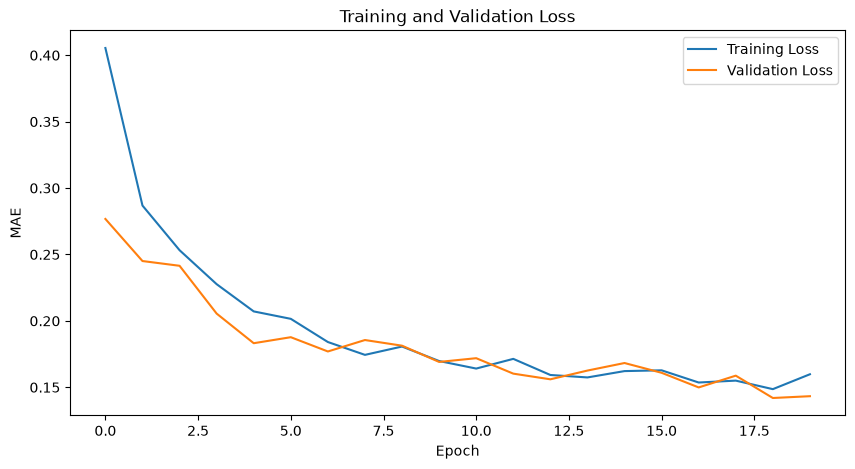

In [50]:
# Plot training history
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training and Validation Loss")

plt.legend()

plt.show()

In [51]:
# Evaluate on the test dataset
test_results = model.evaluate(
    test_ds,
    return_dict=True
)

print(test_results)

27/27 [==============================] - 0s 2ms/step - loss: 0.1445 - MAE: 0.1445 - RMSE: 0.1941
{'loss': 0.14453700184822083, 'MAE': 0.14453700184822083, 'RMSE': 0.19408996403217316}


In [52]:
# Make predictions
y_pred_scaled = model.predict(
    X_test,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_pred_scaled.shape)
print("Actual shape:", y_test.shape)

27/27 [==============================] - 1s 2ms/step
Predictions shape: (840, 5)
Actual shape: (840, 5)


In [53]:
# Convert predictions back to original speed
y_pred = scaler.inverse_transform(y_pred_scaled)

y_actual = scaler.inverse_transform(y_test)

In [54]:
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae = mean_absolute_error(
    y_actual.flatten(),
    y_pred.flatten()
)

rmse = np.sqrt(
    mean_squared_error(
        y_actual.flatten(),
        y_pred.flatten()
    )
)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

MAE:  0.718
RMSE: 0.964


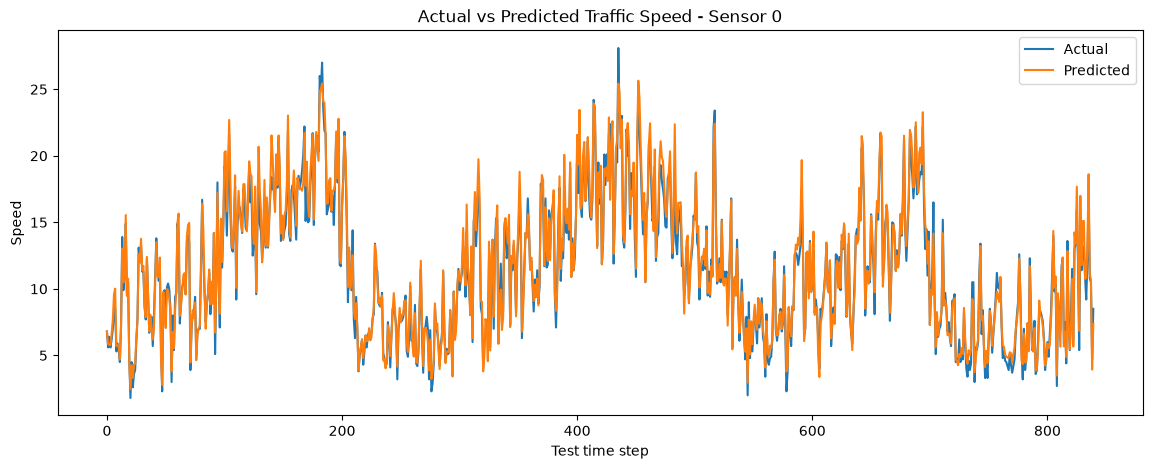

In [55]:
# Compare actual and predicted 
SENSOR_ID = 0

plt.figure(figsize=(14, 5))

plt.plot(
    y_actual[:, SENSOR_ID],
    label="Actual"
)

plt.plot(
    y_pred[:, SENSOR_ID],
    label="Predicted"
)

plt.xlabel("Test time step")
plt.ylabel("Speed")

plt.title(
    f"Actual vs Predicted Traffic Speed - Sensor {SENSOR_ID}"
)

plt.legend()

plt.show()

While the above are the overall test results for all the 7 stations, the MAE is 0.6 much lower than the model developed in Part 2 

3.5 Summary and Comparison 
Compare the GNN + RNN model with the RNN model developed in Part 2 for all five 
weather stations. Use the same test period and evaluation metrics for both models and 
present the results in a clear comparison table similar to the table you provided in Part 
2. 
Summarise the key findings from the GNN+RNN experiments and analyse the 
forecasting performance across the five weather stations. Discuss the effect of 
incorporating spatial information between weather stations on 7-day mean
temperature forecasting and highlight the key differences between the GNN+RNN and 
RNN models.

I think that the model we developed in part 3 with the consideration of the spatial relationship between the nodes gave a much better results than the model that we developed based on the data in one station only. 